In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union





Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA721325/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,ReleaseDate,create_date,version,Sample.Name,SRA.Study,host_body_product,education_group,Host_Age,host_sex,smoke_status
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<int>
1,SRR14212169,AMPLICON,483,15263797,PRJNA721325,SAMN18714371,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",8464628,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,2021-05-12T00:00:00Z,2021-04-12T11:02:00Z,1,o2100,SRP314438,saliva,0,49,female,0
2,SRR14212170,AMPLICON,494,15479560,PRJNA721325,SAMN18714370,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",8391372,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,2021-05-12T00:00:00Z,2021-04-12T11:02:00Z,1,o2099,SRP314438,saliva,0,68,male,2
3,SRR14212171,AMPLICON,354,29354939,PRJNA721325,SAMN18714369,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",15748809,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,2021-05-12T00:00:00Z,2021-04-12T11:02:00Z,1,o2098,SRP314438,saliva,0,44,male,2
4,SRR14212172,AMPLICON,363,11302449,PRJNA721325,SAMN18714368,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",6077517,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,2021-05-12T00:00:00Z,2021-04-12T11:02:00Z,1,o2097,SRP314438,saliva,0,44,male,2
5,SRR14212173,AMPLICON,497,11253389,PRJNA721325,SAMN18714367,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",5985475,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,2021-05-12T00:00:00Z,2021-04-12T11:02:00Z,1,o2096,SRP314438,saliva,0,43,male,1
6,SRR14212174,AMPLICON,495,17786271,PRJNA721325,SAMN18714366,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",9674624,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,2021-05-12T00:00:00Z,2021-04-12T11:03:00Z,1,o2095,SRP314438,saliva,0,37,male,2


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "env_broad_scale"                "env_local_scale"               
[17] "env_medium"                     "Experiment"                    
[19] "geo_loc_name_country"           "geo_loc_name_country_continent"
[21] "geo_loc_name"                   "host_phenotype"                
[23] "HOST"                           "Instrument"                    
[25] "lat_lon"                        "Library.Name"                  
[27] "LibraryLayout"                  "LibrarySelection"              
[29] "LibrarySource"                  "Organism"                      
[31] "Platform"                       "ReleaseDate"                   
[33] "create_date"                    "version"                       
[35] "Sample.Name"                    "SRA.Study"                     
[37] "host_body_product"              "education_group"               
[39] "Host_Age"                       "host_sex"                      
[41] "smoke_status"

In [7]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = initial_meta$Host_Age,
    BMI = NA,
    Sex = initial_meta$host_sex,
    Region = 'V4',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT',
    title = "Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population",
    Disease_study = "NO",
    Status = NA,
    matched_samples = 'NO')

In [8]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 168
[1] 168


In [9]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<int>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA721325,SRR14212169,o2100,49,NA,female,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
2,PRJNA721325,SRR14212170,o2099,68,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
3,PRJNA721325,SRR14212171,o2098,44,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
4,PRJNA721325,SRR14212172,o2097,44,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
5,PRJNA721325,SRR14212173,o2096,43,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
6,PRJNA721325,SRR14212174,o2095,37,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO


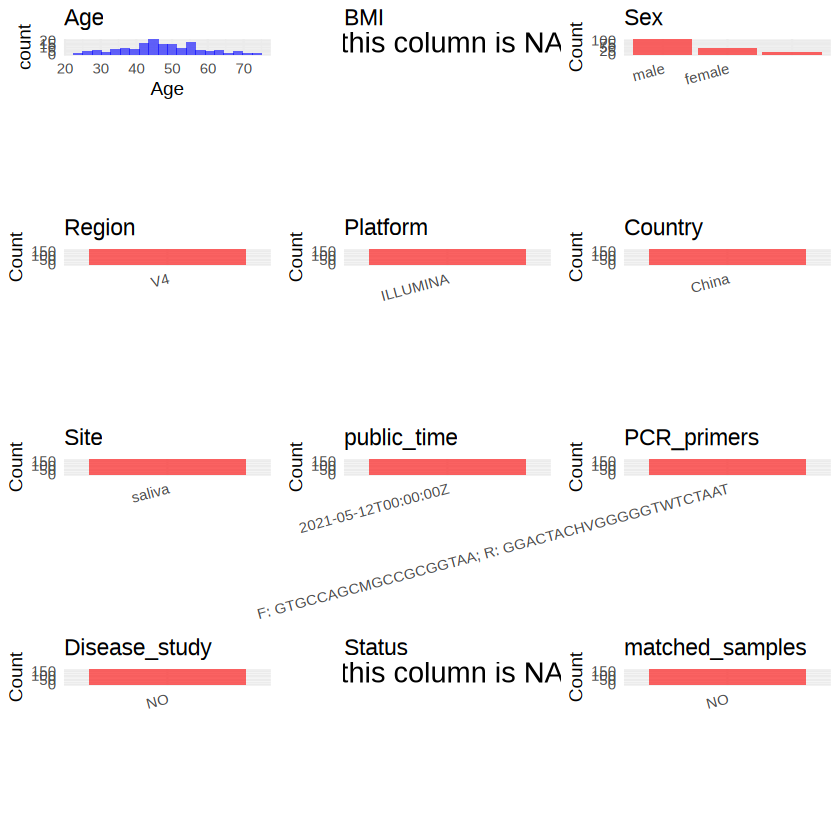

In [10]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [11]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA721325/metadata.csv", quote = T)